# Multi-fidelity inverse solve

Recover `h(x,y)` from a noisy temperature field, using **adaptive KSP tolerance as the
fidelity axis**: start with cheap, loosely-converged linear solves and tighten only when
the optimizer stalls.

Compare against a fixed tight-tolerance baseline on the same problem.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from benchmark_utils import BenchmarkCase, BenchmarkMethod, run_benchmark_case

## 1. The inverse problem

Same setup as `InverseSolve.ipynb`: recover a spatially-varying `h` from `T_obs`.

In [2]:
def h_true(x):
    return 1.0 + 6.0 * x[0] ** 2 + x[0] / (1.0 + 2.0 * x[1] ** 2)


def h0(x):
    return 2.0 + 3.0 * x[0] ** 2 + x[0] / (4.0 + 3.0 * x[1] ** 2)


case = BenchmarkCase(
    name="smooth",
    h_true=h_true,
    h0=h0,
    nmesh=32,
    sigma=1e-3,
    alpha=1e-4,
    observation_noise=1e-3,
    observation_seed=0,
)

## 2. Fidelity schedule  ← the multi-fidelity block

`initial_rtol` sets the starting (cheap, low) fidelity. The controller tightens by
`tighten_factor` once the objective improves by less than `stall_rel_improve` over
`stall_iterations`, or after `rejection_iterations` short steps — down to `min_rtol`.

Forward and adjoint solves always share one tolerance, so the gradient stays consistent
with the objective.

In [3]:
MIT = 200  # equal iteration budget for both methods

ADAPTIVE = {
    "initial_rtol": 1e-5,     # start cheap
    "min_rtol": 1e-10,        # finest fidelity
    "tighten_factor": 0.1,    # one decade per tightening
    "stall_iterations": 3,    # stalled for this many iterations ...
    "stall_rel_improve": 5e-2,  # ... means < 5% objective improvement
    "rejection_iterations": 2,
    "rejected_step_threshold": 0.25,
}

baseline = BenchmarkMethod(
    name="fixed 1e-10",
    forward_petsc_opts={"ksp_rtol": 1e-10},
    mit=MIT,
)

adaptive = BenchmarkMethod(
    name="adaptive 1e-5 -> 1e-10",
    adaptive_ksp_rtol=ADAPTIVE,
    mit=MIT,
)

## 3. Run both

`reason` is TAO's `ConvergedReason`: positive means a tolerance was met, negative means
it stopped for another cause. **Read it before trusting any comparison** — a method that
quits early looks cheap for the wrong reason.

In [4]:
from petsc4py import PETSc

# Decode TAO's reason codes from PETSc itself rather than hard-coding them.
REASONS = {
    v: k
    for k, v in vars(PETSc.TAO.ConvergedReason).items()
    if isinstance(v, int) and not k.startswith("_")
}

results = {m.name: run_benchmark_case(case, m) for m in (baseline, adaptive)}

for name, r in results.items():
    s = r.summary
    print(
        f"{name:24s} KSP={s['total_ksp_iterations']:6d}  TAO={s['tao_iterations']:4d}  "
        f"J={s['final_objective']:.4e}  err={s['h_error_l2_rel']:.4f}  "
        f"{s['wall_time_s']:5.2f}s  "
        f"{REASONS.get(s['converged_reason'], s['converged_reason'])}"
    )

fixed 1e-10              KSP=  2814  TAO= 200  J=1.3459e-01  err=0.1212   0.88s  DIVERGED_MAXITS
adaptive 1e-5 -> 1e-10   KSP=   444  TAO=  54  J=1.5327e-01  err=0.1172   0.40s  DIVERGED_LS_FAILURE


## 4. Did the cheap fidelity pay off?

The claim worth testing is **comparable accuracy for less linear-solver work** — not a
lower objective, and not fewer iterations on their own.

In [5]:
b, a = results[baseline.name].summary, results[adaptive.name].summary

saving = 100 * (1 - a["total_ksp_iterations"] / b["total_ksp_iterations"])
print(f"KSP iterations  : {b['total_ksp_iterations']} -> {a['total_ksp_iterations']}"
      f"  ({saving:.0f}% less work)")
print(f"relative h error: {b['h_error_l2_rel']:.4f} -> {a['h_error_l2_rel']:.4f}")
print(f"tightenings     : {a['ksp_tightenings']}")
print(f"rtol schedule   : {[f'{r:.0e}' for r in a['ksp_rtol_history']]}")
print(f"fwd/adj rtol matched: "
      f"{np.isclose(a['final_forward_ksp_rtol'], a['final_adjoint_ksp_rtol'])}")

if a["h_error_l2_rel"] <= 1.05 * b["h_error_l2_rel"]:
    print(f"\n=> comparable accuracy for {saving:.0f}% less linear-solver work.")
else:
    print(f"\n=> WORSE accuracy -- the schedule is too aggressive for this problem.")

KSP iterations  : 2814 -> 444  (84% less work)
relative h error: 0.1212 -> 0.1172
tightenings     : 2
rtol schedule   : ['1e-05', '1e-06', '1e-07']
fwd/adj rtol matched: True

=> comparable accuracy for 84% less linear-solver work.


**Caveat, and it matters.** Neither method converges to a gradient tolerance here: the
baseline exhausts its iteration budget, and the adaptive run stops on line-search failure
once the loose gradient can no longer support a descent step. The adaptive run is a fair
win on *work for a given accuracy*, not a demonstration of convergence.

Starting looser (`initial_rtol=1e-4`) makes the line search fail almost immediately, at a
much worse objective — the schedule has a floor below which the gradient is too noisy to
optimize against.

## 5. Convergence and the fidelity ladder

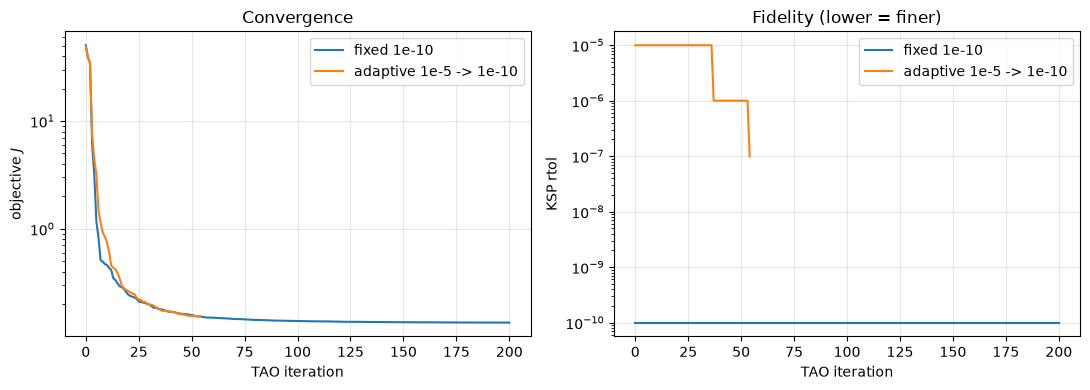

In [6]:
fig, (ax_obj, ax_rtol) = plt.subplots(1, 2, figsize=(11, 4))

for name, r in results.items():
    it = [row["tao_iter"] for row in r.trace]
    ax_obj.semilogy(it, [row["objective"] for row in r.trace], label=name)
    ax_rtol.semilogy(it, [row["forward_ksp_rtol"] for row in r.trace], label=name)

ax_obj.set(xlabel="TAO iteration", ylabel="objective $J$", title="Convergence")
ax_rtol.set(xlabel="TAO iteration", ylabel="KSP rtol", title="Fidelity (lower = finer)")
for ax in (ax_obj, ax_rtol):
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()

## 6. Recovered conductivity

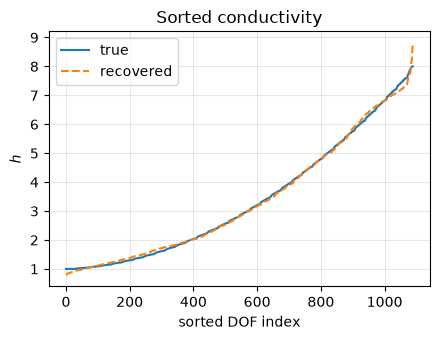

In [7]:
r = results[adaptive.name]
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.plot(np.sort(r.truth), label="true")
ax.plot(np.sort(r.solution), "--", label="recovered")
ax.set(xlabel="sorted DOF index", ylabel="$h$", title="Sorted conductivity")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()